# 2. SAHI: looking at the screen in slices

**The idea.** A tall phone screen is shrunk a lot before the model sees it, so small problems can vanish. SAHI also cuts the screen into overlapping horizontal slices (top, middle, bottom), asks the model about each slice, and combines the answers.

**What you will see.** (1) how the screen is cut, (2) the model's answer on the whole screen, (3) its answer on each slice.

The app keeps SAHI **off** by default because it was not shown to help this model. This notebook lets you judge that yourself. **Green box** = where the defect really is. **Red box** = where the model says it is (approximate).

In [1]:
import sys, time
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import HTML, display
C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'demo_inputs').exists())
sys.path.insert(0, str(C3.parent))
import vision_oracle.services.oracle_service   # must be imported first (path guard for the local package)
from local_vision_oracle.engine import load_inference_contract, contract_messages
from local_vision_oracle import notebook_runs as nr
MODELS = C3 / 'models'
DEMO = C3 / 'demo_inputs'

def banner(title, sub='', color='#1e3a8a'):
    display(HTML(f'<div style="background:{color};color:white;padding:14px 18px;border-radius:8px;margin:14px 0 6px">'
                 f'<div style="font-size:20px;font-weight:700">{title}</div><div style="opacity:.85;margin-top:2px">{sub}</div></div>'))

def show(ax, image, answer=None, gold=None, title='', ok=None):
    ax.imshow(image); ax.axis('off'); W, H = image.size
    g = nr.box_to_pixels(gold, W, H)
    if g: ax.add_patch(Rectangle(g[:2], g[2], g[3], fill=False, ec='lime', lw=3))
    b = nr.box_to_pixels((answer or {}).get('box'), W, H)
    if b and (answer or {}).get('type') not in (None, 'none'): ax.add_patch(Rectangle(b[:2], b[2], b[3], fill=False, ec='red', lw=3))
    ax.set_title(title, fontsize=9, color={True: 'green', False: 'red', None: 'black'}[ok])

def one_line(name, true_type, a):
    ok = a['type'] == true_type
    print(f"{name:<28} said: {a['type']:<18} {'CORRECT' if ok else 'wrong':<8} {a['seconds']:>5.1f} s")
    return ok

from local_vision_oracle.preprocessor import ImagePreprocessor
ADAPTER = 'c3_v3_vision_1ep'
NAME = '01_overlap_team_names.jpg'
TRUE_TYPE, GOLD = nr.SCREENS[NAME]
image = Image.open(DEMO / NAME).convert('RGB')
slices = ImagePreprocessor().get_sahi_slices(image)
print(f'{NAME}: {image.width}x{image.height}, cut into {len(slices)} slices')

01_overlap_team_names.jpg: 1080x1920, cut into 3 slices


## Step 1: how the screen is cut

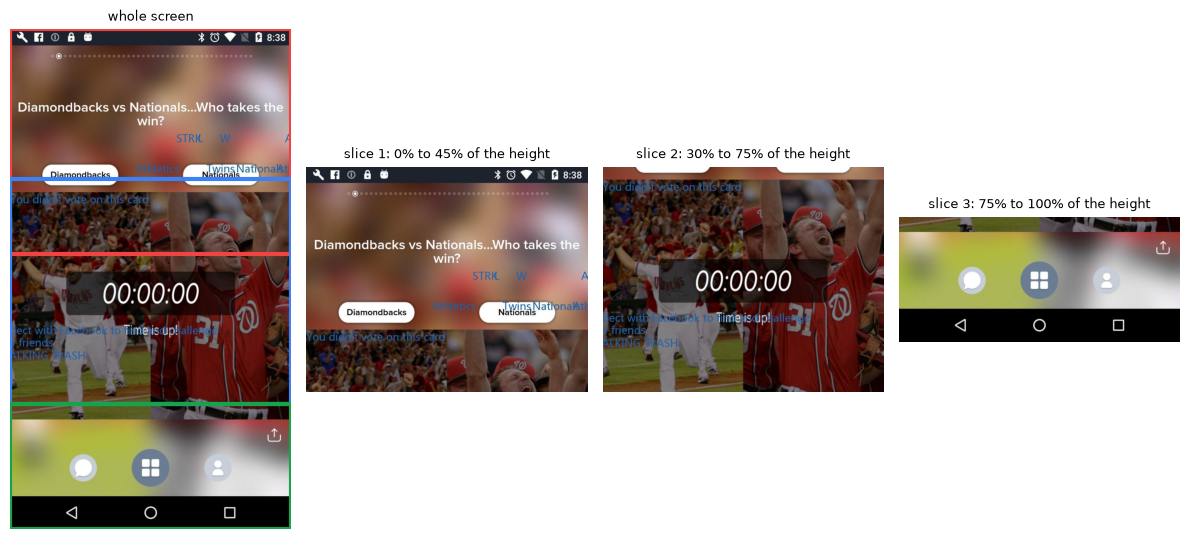

In [2]:
banner('Step 1: the slices', 'Overlap is deliberate, so a defect on a cut line is still whole in one slice', '#475569')
fig, ax = plt.subplots(1, len(slices) + 1, figsize=(3 * (len(slices) + 1), 5.5))
show(ax[0], image, title='whole screen')
cols = ['#ef4444', '#3b82f6', '#16a34a']
for s in slices:
    x1, y1, x2, y2 = s.crop_box
    ax[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=cols[s.slice_index % 3], lw=3))
    show(ax[s.slice_index + 1], s.image, title=f'slice {s.slice_index + 1}: {s.y_start_ratio:.0%} to {s.y_end_ratio:.0%} of the height')
plt.tight_layout(); plt.show()

## Step 2 and 3: ask the model about the whole screen, then each slice

In [3]:
banner('Loading the shipped model (v3 vision)', 'About 30 seconds', '#166534')
contract = load_inference_contract(str(MODELS / ADAPTER)); messages = contract_messages(contract)
backend = nr.load_backend(MODELS, ADAPTER)
whole = nr.run_once(backend, image, messages)
tiles = [nr.run_once(backend, s.image, messages) for s in slices]
nr.free_backend(backend)
print('model released')

C:\Users\hp\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/729 [00:01<20:21,  1.68s/it]

Loading weights:   0%|          | 3/729 [00:01<05:50,  2.07it/s]

Loading weights:   1%|          | 4/729 [00:01<04:16,  2.82it/s]

...

Loading weights:  94%|█████████▍| 686/729 [00:08<00:00, 182.37it/s]

Loading weights:  97%|█████████▋| 705/729 [00:08<00:00, 178.39it/s]

Loading weights: 100%|█████████▉| 726/729 [00:08<00:00, 151.09it/s]

Loading weights: 100%|██████████| 729/729 [00:08<00:00, 81.55it/s] 

model released


whole screen                 said: component_overlap  CORRECT    6.0 s
slice 1                      said: text_truncation    wrong      5.9 s
slice 2                      said: component_overlap  CORRECT    5.4 s
slice 3                      said: missing_component  wrong      5.5 s


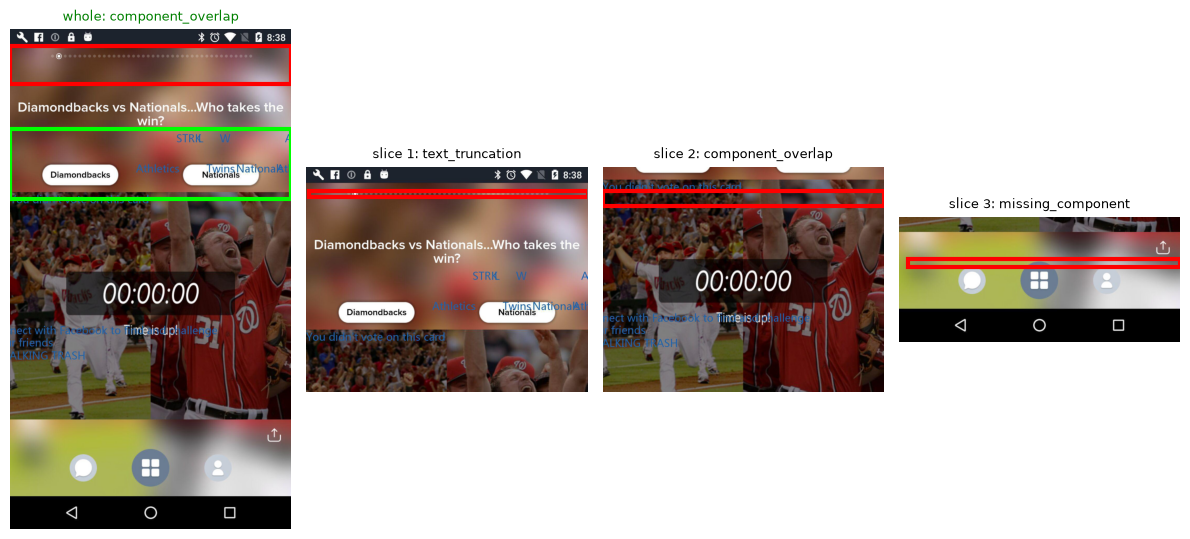

Cost: whole screen 6.0 s, whole + 3 slices 22.8 s (3.8x the time).


In [4]:
banner('Result', f'True defect: {TRUE_TYPE}', '#166534')
ok = one_line('whole screen', TRUE_TYPE, whole)
for i, t in enumerate(tiles, 1): one_line(f'slice {i}', TRUE_TYPE, t)
fig, ax = plt.subplots(1, len(slices) + 1, figsize=(3 * (len(slices) + 1), 5.5))
show(ax[0], image, whole, GOLD, f"whole: {whole['type']}", whole['type'] == TRUE_TYPE)
for i, (s, t) in enumerate(zip(slices, tiles), 1):
    show(ax[i], s.image, t, None, f"slice {i}: {t['type']}", None)
plt.tight_layout(); plt.show()
t_whole, t_all = whole['seconds'], sum(t['seconds'] for t in tiles) + whole['seconds']
print(f'Cost: whole screen {t_whole:.1f} s, whole + {len(slices)} slices {t_all:.1f} s ({t_all / t_whole:.1f}x the time).')

## What to conclude
Compare the slice answers with the whole-screen answer. If the slices find the true defect type where the whole screen did not, SAHI helps on this screen; if they disagree with the truth or flag extra problems, it adds cost and noise. One screen is an illustration, not a result, which is why the app leaves SAHI off.